# LightGBM Additional Benchmark
Uses the active ordinal-encoded tree branch and the same validation-only threshold protocol as the core models.

## 1. Imports and configuration

In [13]:
from __future__ import annotations

from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve)

cwd = Path.cwd().resolve()
if (cwd / 'Source' / 'src').is_dir():
    REPO_ROOT = cwd
elif cwd.name == 'notebooks' and cwd.parent.name == 'Source':
    REPO_ROOT = cwd.parent.parent
else:
    raise RuntimeError(f'Cannot resolve repository root from {cwd}')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print('Repository root:', REPO_ROOT)

from Source.src.path import DATA_REPORTS_DIR, FIGURES_DIR, TRAIN_DATA_FILE, VALIDATION_DATA_FILE, TEST_DATA_FILE
from Source.src.utils.feature_display import build_feature_mapping_table

warnings.filterwarnings('default')
RANDOM_STATE = 42
DEFAULT_THRESHOLD = 0.50
TARGET_RECALL = 0.85
F1_TOLERANCE = 1e-6
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)
TOP_N_FEATURES = 15
MODEL_NAME = 'LightGBM'
assert len(THRESHOLDS) == 91
print('Model:', MODEL_NAME)
print('Threshold candidates:', len(THRESHOLDS), THRESHOLDS[0], THRESHOLDS[-1])


Repository root: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1
Model: LightGBM
Threshold candidates: 91 0.05 0.95


## 2. Output directory setup

In [14]:
required_paths = [DATA_REPORTS_DIR, FIGURES_DIR, TRAIN_DATA_FILE, VALIDATION_DATA_FILE, TEST_DATA_FILE]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f'Missing required paths; stopping before run_pipeline: {missing_paths}')
print('Data reports directory:', DATA_REPORTS_DIR)
print('Figures directory:', FIGURES_DIR)
print('All checkpoints exist; ingestion must remain skipped.')


Data reports directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports
Figures directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures
All checkpoints exist; ingestion must remain skipped.


## 3. Evaluation and export helpers

In [15]:
def save_table(df: pd.DataFrame, filename: str) -> Path:
    path = DATA_REPORTS_DIR / filename
    df.to_csv(path, index=False)
    print(f'Saved {filename}: shape={df.shape}')
    return path

def save_figure(filename: str) -> Path:
    path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches='tight')
    print('Saved 300-DPI figure:', path)
    plt.show()
    plt.close()
    return path

def evaluate(y_true, y_proba, threshold: float, split: str) -> pd.DataFrame:
    y_true = np.asarray(y_true).astype(int)
    y_proba = np.asarray(y_proba)
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return pd.DataFrame([{
        'Model': MODEL_NAME, 'Split': split, 'Threshold': float(threshold),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1_Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_proba),
        'PR_AUC': average_precision_score(y_true, y_proba),
        'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn),
        'False_Positive_Rate': fp / (fp + tn) if fp + tn else 0.0,
        'False_Negative_Rate': fn / (fn + tp) if fn + tp else 0.0,
    }])

def scan_thresholds(y_true, y_proba) -> pd.DataFrame:
    table = pd.concat([evaluate(y_true, y_proba, t, 'validation') for t in THRESHOLDS], ignore_index=True)
    table['Meets_Recall_Target'] = table['Recall'] >= TARGET_RECALL
    if len(table) != 91:
        raise RuntimeError(f'Expected 91 threshold rows, got {len(table)}')
    return table

def select_threshold(table: pd.DataFrame):
    eligible = table[table['Recall'] >= TARGET_RECALL].copy()
    if not eligible.empty:
        max_f1 = eligible['F1_Score'].max()
        tied = eligible[eligible['F1_Score'] >= max_f1 - F1_TOLERANCE]
        selected = tied.sort_values(['Precision', 'Threshold'], ascending=[False, False]).iloc[0]
        met = True
        rule = 'Recall target met; highest F1 with 1e-6 tolerance, then higher precision and threshold.'
    else:
        selected = table.sort_values(['Recall', 'F1_Score', 'Precision', 'Threshold'], ascending=[False]*4).iloc[0]
        met = False
        rule = 'Recall target not met; highest recall, then F1, precision, and threshold.'
    return float(selected['Threshold']), bool(met), rule

def confusion_table(y_true, y_proba, threshold, split):
    pred = (np.asarray(y_proba) >= threshold).astype(int)
    matrix = confusion_matrix(y_true, pred, labels=[0, 1])
    return pd.DataFrame([
        {'Split': split, 'Threshold': threshold, 'Actual': actual, 'Predicted': predicted, 'Count': int(matrix[i, j])}
        for i, actual in enumerate([0, 1]) for j, predicted in enumerate([0, 1])])

def report_table(y_true, y_proba, threshold, split):
    pred = (np.asarray(y_proba) >= threshold).astype(int)
    report = pd.DataFrame(classification_report(y_true, pred, labels=[0, 1], output_dict=True, zero_division=0)).T
    report = report.reset_index().rename(columns={'index': 'Class'})
    report.insert(0, 'Threshold', threshold)
    report.insert(0, 'Split', split)
    return report

def plot_confusion(y_true, y_proba, threshold, title):
    matrix = confusion_matrix(y_true, (np.asarray(y_proba) >= threshold).astype(int), labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(matrix, cmap='Blues')
    ax.set(title=title, xlabel='Predicted label', ylabel='Actual label', xticks=[0, 1], yticks=[0, 1])
    ax.set_xticklabels(['No Churn', 'Churn']); ax.set_yticklabels(['No Churn', 'Churn'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(matrix[i, j]), ha='center', va='center', color='white' if matrix[i, j] > matrix.max()/2 else 'black')
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)


## 4. Load pipeline outputs

In [16]:
from Source.src.main import run_pipeline
result = run_pipeline(force_ingestion=False, use_database=False)
builder = result['builder']
outputs = result['outputs']
tree_train = outputs['tree']['train']
tree_val = outputs['tree']['validation']
tree_test = outputs['tree']['test']
print("Pipeline branch used: outputs['tree'] only")
print('Tree shapes:', tree_train.shape, tree_val.shape, tree_test.shape)


2026-07-13 16:54:27,997 - main - [INFO] - Refactored churn pipeline orchestration started.
2026-07-13 16:54:28,000 - main - [INFO] - Run options: force_ingestion=False, use_database=False, view_name=None
2026-07-13 16:54:28,001 - main - [INFO] - Train checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\train_df.csv
2026-07-13 16:54:28,003 - main - [INFO] - Validation checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\validation_df.csv
2026-07-13 16:54:28,005 - main - [INFO] - Test checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\test_df.csv
2026-07-13 16:54:28,006 - main - [INFO] - All checkpoint files exist; ingestion skipped.
2026-07-13 16:54:28,058 - main - [INFO] - Loaded train checkpoint shape: (4930, 16)
2026-07-13 16:54:28,058 - main - [INFO] - Loaded validation checkpoint shape: (1056,

All required project directories are available.


2026-07-13 16:54:28,312 - main - [INFO] - Logistic train output shape: (4930, 28)
2026-07-13 16:54:28,314 - main - [INFO] - Logistic validation output shape: (1056, 28)
2026-07-13 16:54:28,315 - main - [INFO] - Logistic test output shape: (1057, 28)
2026-07-13 16:54:28,316 - main - [INFO] - Tree train output shape: (4930, 20)
2026-07-13 16:54:28,316 - main - [INFO] - Tree validation output shape: (1056, 20)
2026-07-13 16:54:28,316 - main - [INFO] - Tree test output shape: (1057, 20)
2026-07-13 16:54:28,316 - main - [INFO] - Preprocessing branch orchestration completed.
2026-07-13 16:54:28,316 - main - [INFO] - Refactored churn pipeline orchestration finished.


Pipeline branch used: outputs['tree'] only
Tree shapes: (4930, 20) (1056, 20) (1057, 20)


## 5. Validate splits and prepare X/y

In [17]:
expected_tree = {'train': (4930, 20), 'validation': (1056, 20), 'test': (1057, 20)}
frames = {'train': tree_train, 'validation': tree_val, 'test': tree_test}
for name, frame in frames.items():
    assert frame.shape == expected_tree[name], (name, frame.shape)
    assert {'ID', 'Churn'}.issubset(frame.columns)

X_train = tree_train.drop(columns=['ID', 'Churn']); y_train = tree_train['Churn'].astype(int)
X_val = tree_val.drop(columns=['ID', 'Churn']); y_val = tree_val['Churn'].astype(int)
X_test = tree_test.drop(columns=['ID', 'Churn']); y_test = tree_test['Churn'].astype(int)
expected_x = {'train': (4930, 18), 'validation': (1056, 18), 'test': (1057, 18)}
x_frames = {'train': X_train, 'validation': X_val, 'test': X_test}
for name, frame in x_frames.items():
    assert frame.shape == expected_x[name]
    assert list(frame.columns) == list(X_train.columns)
    assert 'ID' not in frame and 'Churn' not in frame
    assert not frame.select_dtypes(include=['object', 'category']).columns.tolist()
    assert not frame.isna().any().any()
    assert np.isfinite(frame.to_numpy(dtype=float)).all()
for name, target in {'train': y_train, 'validation': y_val, 'test': y_test}.items():
    assert set(target.unique()).issubset({0, 1}) and target.notna().all()
print('X/y shapes:', X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape)
print('Feature columns:', X_train.columns.tolist())
print('Training class distribution:'); display(y_train.value_counts().sort_index().rename('count'))


X/y shapes: (4930, 18) (4930,) (1056, 18) (1056,) (1057, 18) (1057,)
Feature columns: ['SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'tenure_group', 'service_diversity', 'monthly_charges_ratio', 'is_paperless_electronic']
Training class distribution:


Churn
0    3622
1    1308
Name: count, dtype: int64

## 6. Model configuration and training

In [18]:
lightgbm_model = LGBMClassifier(objective='binary', n_estimators=300, learning_rate=0.05, num_leaves=31,
    max_depth=-1, subsample=0.9, subsample_freq=1, colsample_bytree=0.9, class_weight='balanced',
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1)
print('Model parameters:', lightgbm_model.get_params())
lightgbm_model.fit(X_train, y_train)
validation_probability = lightgbm_model.predict_proba(X_val)[:, 1]
print('Training completed; validation probability shape:', validation_probability.shape)


Model parameters: {'boosting_type': 'gbdt', 'class_weight': 'balanced', 'colsample_bytree': 0.9, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 300, 'n_jobs': -1, 'num_leaves': 31, 'objective': 'binary', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.9, 'subsample_for_bin': 200000, 'subsample_freq': 1, 'verbosity': -1}
Training completed; validation probability shape: (1056,)


## 7. Default validation evaluation

,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate
0,LightGBM,validation,0.5,0.779356,0.562334,0.757143,0.645358,0.848523,0.651637,212,165,611,68,0.212629,0.242857


Saved lightgbm_default_threshold_validation_metrics.csv: shape=(1, 15)
Saved lightgbm_validation_confusion_matrix_default_threshold.csv: shape=(4, 5)
Saved lightgbm_validation_classification_report_default_threshold.csv: shape=(5, 7)
Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\lightgbm_01_validation_confusion_matrix_default_threshold.png


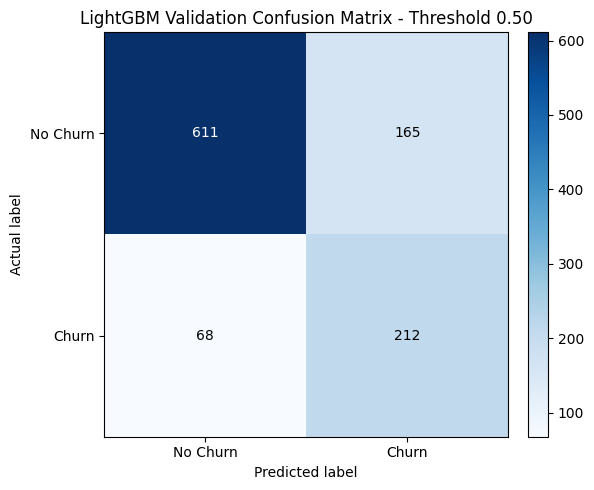

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/lightgbm_01_validation_confusion_matrix_default_threshold.png')

In [19]:
default_metrics = evaluate(y_val, validation_probability, DEFAULT_THRESHOLD, 'validation')
display(default_metrics)
save_table(default_metrics, 'lightgbm_default_threshold_validation_metrics.csv')
save_table(confusion_table(y_val, validation_probability, DEFAULT_THRESHOLD, 'validation'), 'lightgbm_validation_confusion_matrix_default_threshold.csv')
save_table(report_table(y_val, validation_probability, DEFAULT_THRESHOLD, 'validation'), 'lightgbm_validation_classification_report_default_threshold.csv')
plot_confusion(y_val, validation_probability, DEFAULT_THRESHOLD, 'LightGBM Validation Confusion Matrix - Threshold 0.50')
save_figure('lightgbm_01_validation_confusion_matrix_default_threshold.png')


## 8. Threshold sensitivity and validation selection

Saved lightgbm_threshold_sensitivity_validation.csv: shape=(91, 16)


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target,Target_Recall,Recall_Target_Met,Selection_Rule
0,LightGBM,validation,0.27,0.724432,0.488798,0.857143,0.622568,0.848523,0.651637,240,251,525,40,0.323454,0.142857,True,0.85,True,Recall target met; highest F1 with 1e-6 tolera...


Selected validation threshold: 0.27
Saved lightgbm_selected_threshold_validation_metrics.csv: shape=(1, 19)
Saved lightgbm_validation_confusion_matrix_selected_threshold.csv: shape=(4, 5)
Saved lightgbm_validation_classification_report_selected_threshold.csv: shape=(5, 7)
Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\lightgbm_02_threshold_sensitivity_validation.png


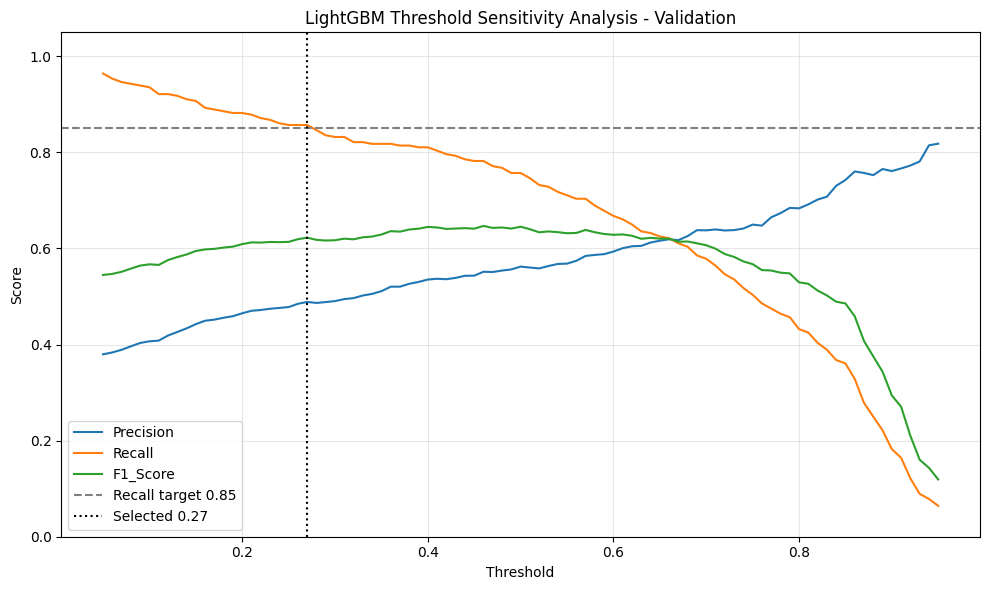

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/lightgbm_02_threshold_sensitivity_validation.png')

In [20]:
threshold_table = scan_thresholds(y_val, validation_probability)
save_table(threshold_table, 'lightgbm_threshold_sensitivity_validation.csv')
selected_threshold, recall_target_met, selection_rule = select_threshold(threshold_table)
selected_validation = evaluate(y_val, validation_probability, selected_threshold, 'validation')
selected_validation['Meets_Recall_Target'] = selected_validation['Recall'] >= TARGET_RECALL
selected_validation['Target_Recall'] = TARGET_RECALL
selected_validation['Recall_Target_Met'] = recall_target_met
selected_validation['Selection_Rule'] = selection_rule
display(selected_validation)
print('Selected validation threshold:', selected_threshold)
save_table(selected_validation, 'lightgbm_selected_threshold_validation_metrics.csv')
save_table(confusion_table(y_val, validation_probability, selected_threshold, 'validation'), 'lightgbm_validation_confusion_matrix_selected_threshold.csv')
save_table(report_table(y_val, validation_probability, selected_threshold, 'validation'), 'lightgbm_validation_classification_report_selected_threshold.csv')
fig, ax = plt.subplots(figsize=(10, 6))
for metric in ['Precision', 'Recall', 'F1_Score']: ax.plot(threshold_table['Threshold'], threshold_table[metric], label=metric)
ax.axhline(TARGET_RECALL, color='gray', linestyle='--', label='Recall target 0.85')
ax.axvline(selected_threshold, color='black', linestyle=':', label=f'Selected {selected_threshold:.2f}')
ax.set(title='LightGBM Threshold Sensitivity Analysis - Validation', xlabel='Threshold', ylabel='Score', ylim=(0, 1.05)); ax.grid(alpha=.3); ax.legend()
save_figure('lightgbm_02_threshold_sensitivity_validation.png')


## 9. Validation ROC and precision-recall curves

Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\lightgbm_03_roc_curve_validation.png


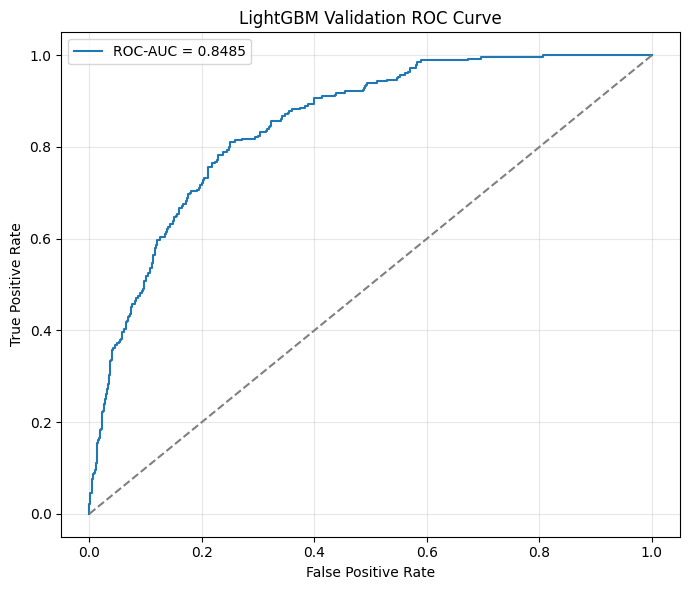

Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\lightgbm_04_precision_recall_curve_validation.png


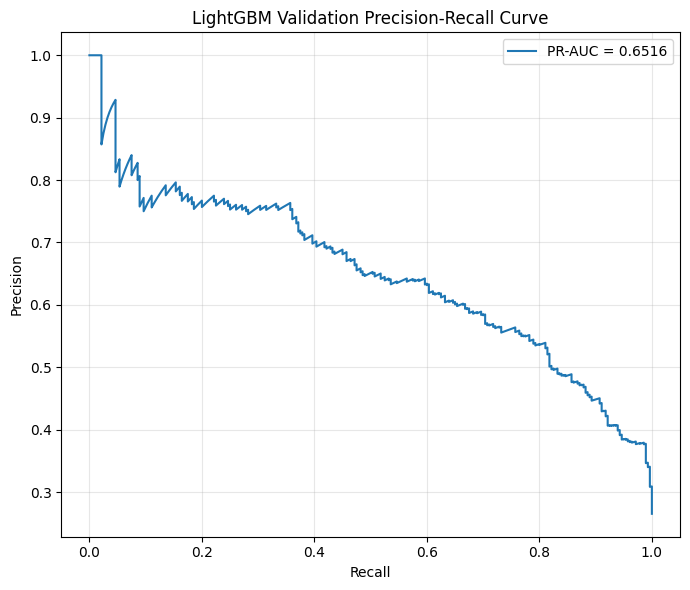

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/lightgbm_04_precision_recall_curve_validation.png')

In [21]:
fpr, tpr, _ = roc_curve(y_val, validation_probability)
plt.figure(figsize=(7, 6)); plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc_score(y_val, validation_probability):.4f}'); plt.plot([0,1],[0,1],'--',color='gray'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('LightGBM Validation ROC Curve'); plt.grid(alpha=.3); plt.legend()
save_figure('lightgbm_03_roc_curve_validation.png')
precision, recall, _ = precision_recall_curve(y_val, validation_probability)
plt.figure(figsize=(7, 6)); plt.plot(recall, precision, label=f'PR-AUC = {average_precision_score(y_val, validation_probability):.4f}'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('LightGBM Validation Precision-Recall Curve'); plt.grid(alpha=.3); plt.legend()
save_figure('lightgbm_04_precision_recall_curve_validation.png')


## 10. Final frozen-threshold test evaluation

,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Threshold_Source
0,LightGBM,test,0.27,0.703879,0.469349,0.871886,0.610212,0.83169,0.639849,245,277,499,36,0.356959,0.128114,validation


Saved lightgbm_selected_threshold_test_metrics.csv: shape=(1, 16)
Saved lightgbm_test_confusion_matrix_selected_threshold.csv: shape=(4, 5)
Saved lightgbm_test_classification_report_selected_threshold.csv: shape=(5, 7)
Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\lightgbm_05_test_confusion_matrix_selected_threshold.png


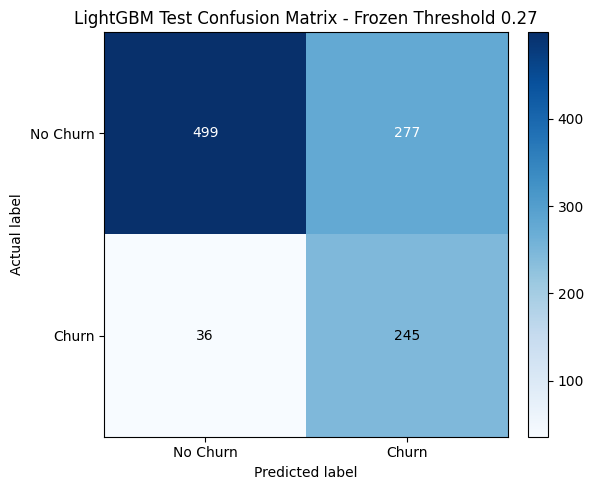

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/lightgbm_05_test_confusion_matrix_selected_threshold.png')

In [22]:
test_probability = lightgbm_model.predict_proba(X_test)[:, 1]
test_metrics = evaluate(y_test, test_probability, selected_threshold, 'test')
test_metrics['Threshold_Source'] = 'validation'
display(test_metrics)
save_table(test_metrics, 'lightgbm_selected_threshold_test_metrics.csv')
save_table(confusion_table(y_test, test_probability, selected_threshold, 'test'), 'lightgbm_test_confusion_matrix_selected_threshold.csv')
save_table(report_table(y_test, test_probability, selected_threshold, 'test'), 'lightgbm_test_classification_report_selected_threshold.csv')
plot_confusion(y_test, test_probability, selected_threshold, f'LightGBM Test Confusion Matrix - Frozen Threshold {selected_threshold:.2f}')
save_figure('lightgbm_05_test_confusion_matrix_selected_threshold.png')


## 11. Gain-based feature importance

Saved feature_name_mapping_lightgbm.csv: shape=(18, 9)
Saved lightgbm_feature_importance.csv: shape=(18, 13)
Saved lightgbm_top_feature_importance.csv: shape=(15, 13)


,Rank,Feature_Display_Name,Importance
0,1,Contract Type,12816.675136
1,2,Monthly Charges,8762.445112
2,3,Tenure,5872.901550
3,4,Total Charges,5797.801081
4,5,Dependents,3182.190584
5,6,Payment Method,1256.018465
6,7,Monthly Charges Ratio,1211.770971
7,8,Service Diversity Score,1074.781000
8,9,Paperless Billing,785.884680
9,10,Partner,714.331698


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\lightgbm_06_top_feature_importance.png


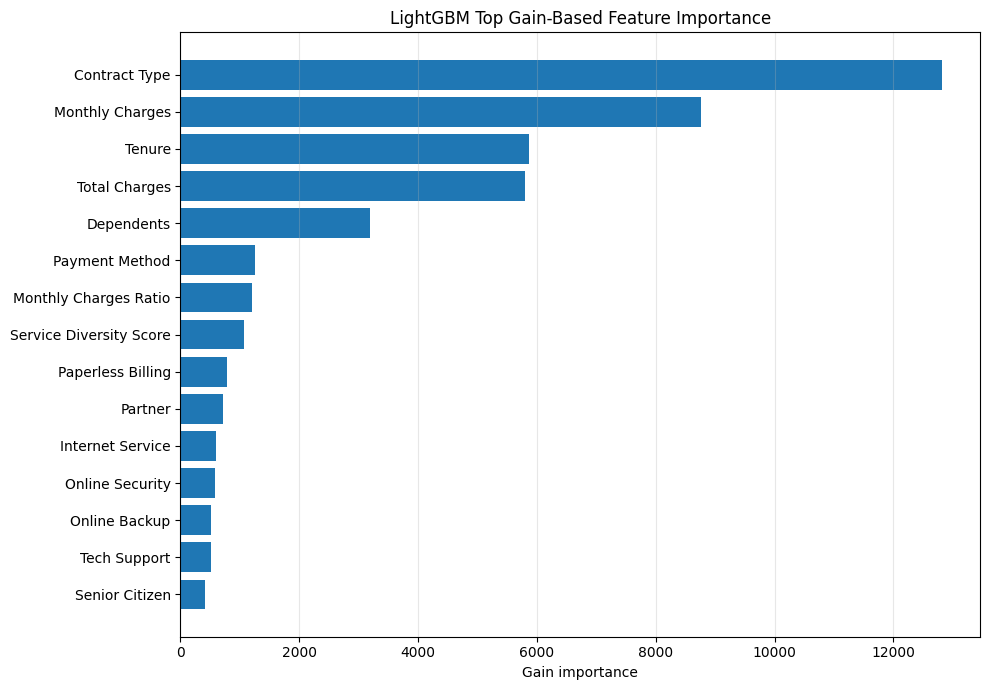

Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\lightgbm_07_cumulative_feature_importance.png


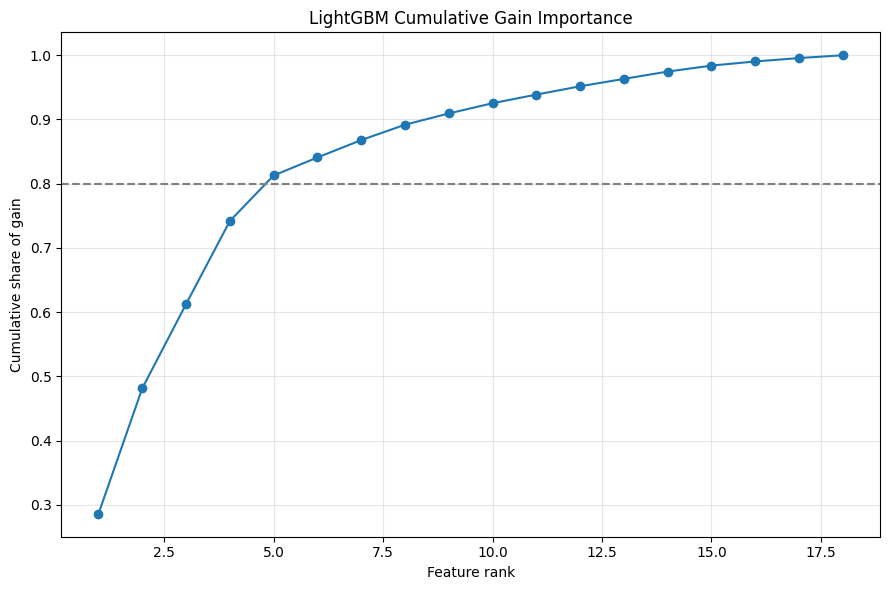

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/lightgbm_07_cumulative_feature_importance.png')

In [23]:
mapping = build_feature_mapping_table(X_train.columns)
save_table(mapping, 'feature_name_mapping_lightgbm.csv')
importance = mapping.copy()
importance.insert(0, 'Model', MODEL_NAME)
importance['Importance_Type'] = 'LightGBM gain'
importance['Importance'] = lightgbm_model.booster_.feature_importance(importance_type='gain').astype(float)
importance = importance.sort_values('Importance', ascending=False).reset_index(drop=True)
importance['Rank'] = np.arange(1, len(importance)+1)
save_table(importance, 'lightgbm_feature_importance.csv')
top_importance = importance.head(TOP_N_FEATURES).copy()
save_table(top_importance, 'lightgbm_top_feature_importance.csv')
display(top_importance[['Rank','Feature_Display_Name','Importance']])
plot_df = top_importance.iloc[::-1]
plt.figure(figsize=(10, 7)); plt.barh(plot_df['Feature_Display_Name'], plot_df['Importance']); plt.xlabel('Gain importance'); plt.title('LightGBM Top Gain-Based Feature Importance'); plt.grid(axis='x', alpha=.3)
save_figure('lightgbm_06_top_feature_importance.png')
cumulative = importance['Importance'].cumsum() / importance['Importance'].sum()
plt.figure(figsize=(9, 6)); plt.plot(importance['Rank'], cumulative, marker='o'); plt.axhline(.8, color='gray', linestyle='--'); plt.xlabel('Feature rank'); plt.ylabel('Cumulative share of gain'); plt.title('LightGBM Cumulative Gain Importance'); plt.grid(alpha=.3)
save_figure('lightgbm_07_cumulative_feature_importance.png')


## 12. Final execution summary

In [24]:
expected_csv = ['lightgbm_default_threshold_validation_metrics.csv','lightgbm_threshold_sensitivity_validation.csv','lightgbm_selected_threshold_validation_metrics.csv','lightgbm_selected_threshold_test_metrics.csv','lightgbm_feature_importance.csv','lightgbm_top_feature_importance.csv','feature_name_mapping_lightgbm.csv','lightgbm_validation_confusion_matrix_default_threshold.csv','lightgbm_validation_confusion_matrix_selected_threshold.csv','lightgbm_test_confusion_matrix_selected_threshold.csv','lightgbm_validation_classification_report_default_threshold.csv','lightgbm_validation_classification_report_selected_threshold.csv','lightgbm_test_classification_report_selected_threshold.csv']
expected_figures = [f'lightgbm_{i:02d}_{name}.png' for i, name in enumerate(['validation_confusion_matrix_default_threshold','threshold_sensitivity_validation','roc_curve_validation','precision_recall_curve_validation','test_confusion_matrix_selected_threshold','top_feature_importance','cumulative_feature_importance'], 1)]
missing = [str(DATA_REPORTS_DIR/f) for f in expected_csv if not (DATA_REPORTS_DIR/f).exists()] + [str(FIGURES_DIR/f) for f in expected_figures if not (FIGURES_DIR/f).exists()]
if missing: raise FileNotFoundError(missing)
assert len(pd.read_csv(DATA_REPORTS_DIR/'lightgbm_threshold_sensitivity_validation.csv')) == 91
print('LightGBM benchmark completed successfully.')
print('Pipeline branch: tree; selected threshold source: validation; final evaluation: test')
print('Default validation metrics:'); display(default_metrics)
print('Selected validation metrics:'); display(selected_validation)
print('Final test metrics:'); display(test_metrics)
print('Output files:', expected_csv + expected_figures)


LightGBM benchmark completed successfully.
Pipeline branch: tree; selected threshold source: validation; final evaluation: test
Default validation metrics:


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate
0,LightGBM,validation,0.5,0.779356,0.562334,0.757143,0.645358,0.848523,0.651637,212,165,611,68,0.212629,0.242857


Selected validation metrics:


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target,Target_Recall,Recall_Target_Met,Selection_Rule
0,LightGBM,validation,0.27,0.724432,0.488798,0.857143,0.622568,0.848523,0.651637,240,251,525,40,0.323454,0.142857,True,0.85,True,Recall target met; highest F1 with 1e-6 tolera...


Final test metrics:


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Threshold_Source
0,LightGBM,test,0.27,0.703879,0.469349,0.871886,0.610212,0.83169,0.639849,245,277,499,36,0.356959,0.128114,validation


Output files: ['lightgbm_default_threshold_validation_metrics.csv', 'lightgbm_threshold_sensitivity_validation.csv', 'lightgbm_selected_threshold_validation_metrics.csv', 'lightgbm_selected_threshold_test_metrics.csv', 'lightgbm_feature_importance.csv', 'lightgbm_top_feature_importance.csv', 'feature_name_mapping_lightgbm.csv', 'lightgbm_validation_confusion_matrix_default_threshold.csv', 'lightgbm_validation_confusion_matrix_selected_threshold.csv', 'lightgbm_test_confusion_matrix_selected_threshold.csv', 'lightgbm_validation_classification_report_default_threshold.csv', 'lightgbm_validation_classification_report_selected_threshold.csv', 'lightgbm_test_classification_report_selected_threshold.csv', 'lightgbm_01_validation_confusion_matrix_default_threshold.png', 'lightgbm_02_threshold_sensitivity_validation.png', 'lightgbm_03_roc_curve_validation.png', 'lightgbm_04_precision_recall_curve_validation.png', 'lightgbm_05_test_confusion_matrix_selected_threshold.png', 'lightgbm_06_top_feat